# Evaluating the Big-Five Loop

In this notebook, we are going to evaluate the workflow:

1. Generate a personality description, $p$, based on the specified Big-Five scores, $S$ (with [our utility script](https://github.com/tingsyo/ai-subject/blob/main/persona/utils/generate_persona_from_ocean.py)).
2. Ask LLMs to use $P$ to respond to the **[Big-Five-50](https://ipip.ori.org/new_ipip-50-item-scale.htm)** questionnaire, $Q$ (with [our utility script](https://github.com/tingsyo/ai-subject/blob/main/likert_questionnaire/utils/evaluate_persona.py)).

We want to see if $Q(p)$ can match the original $S$.

Since each $p$ is generated based on the **percentile rank (PR)** of the five personality traits, we need to generate a certain number of $p$s so that we can derive the PR of $Q(p)$.

## Generate Personality Descriptions

We generate the personality descriptions with specified PR ranks of the Big-Five personality traits:

$p = LLM(S)$,

$S = (o, c, e, a, n)$

where $o, c, e, a, n \in [0, 100]$.

We don't know how sensitive the $LLM$ is to changes in $S$, so it is hard to determine which $S$ values to use. Hence, we perform a simple estimation before we define the values of $S$. Since the values in $S$ are percentile ranks, an arithmetic sequence from 5 to 95 with an increment of 5 should be a suitable choice. Thus, each of the $(o, c, e, a, n)$ has 10 values, and together they form a set of $10^5 = 100,000$ values.

Although generating $100,000$ personality descriptions is computationally feasible, it might be too costly for a pilot study. While we still want to assess an $ LLM$'s sensitivity in generating personality descriptions, we can fix the PR values of the other four personality traits while varying one. We varied one dimension with 21 values, while the other four dimensions are fixed to `[0, 25, 50, 75, 100]`. Here we have $21 \times 5 \times 5  - 21 = 504$ values of $S_{high}$.

In addition, we add a grid of a lower resolution: `[5, 35, 65, 95]` (an arithmetic sequence from 5 to 95 with an increment of 30) as a supplement to the whole search space of the $(o, c, e, a, n)$. As a result, we have $4^5 = 1,024$ values of $S_{low}$ to capture the larger change.

By combining $S_{high}$ and $S_{low}$ and removing redundant values, we obtain a set of $S$ with $1,529$ values. The generated personality descriptions of  $S_{high}$ and $S_{low}$ can be found in the repo ([here](https://github.com/tingsyo/ai-subject/tree/main/persona/data/bfint5_gemma4e4b_t00) and [here](https://github.com/tingsyo/ai-subject/tree/main/persona/data/gemma4_e4b_00)).

## Respond to the Questionnaire with Generated Personality Description

As shown in the previous notebooks ([01](https://github.com/tingsyo/ai-subject/blob/main/likert_questionnaire/reports/01_Reproducibility_of_LLM_Respondents.ipynb) and [02](https://github.com/tingsyo/ai-subject/blob/main/likert_questionnaire/reports/02_Reproducibility_with_random_seeds.ipynb)), we can reproduce the same response by setting the parameter `temperature=0.0`. We then use the identical LLM calls to get the responses of the questionnaire while varying the personality description.

The responses of $1,529$ personality descriptions can be found [here](https://github.com/tingsyo/ai-subject/tree/main/likert_questionnaire/output/temp00).


## Evaluate the Responses

We obtained the questionnaire from the [Open-Source Psychometrics Project](https://openpsychometrics.org/tests/IPIP-BFFM/). These five scales were developed to measure the Big-Five factor markers reported in the following article: *Goldberg, L. R. (1992). The development of markers for the Big-Five factor structure. Psychological Assessment, 4, 26-42*. The five factors are:

1. Extraversion (E) measures boldness, energy, and social interactivity.
2. Agreeableness (A) measures kindness, helpfulness, and willingness to cooperate.
3. Conscientiousness (C) measures self-control, diligence, and attention to detail.
4. Emotional Stability (Neuroticism Inverse, -N) measures depression, irritability, and proneness to anxiety.
5. Intellect/Imagination (openness, O) measures creativity, curiosity, and willingness to entertain new ideas.

For an easier scoring process, we use the following scheme:

```
[
{ "id": 1, "text": "Am the life of the party", "domain": "E", "keyed": "+" },
{ "id": 2, "text": "Feel little concern for others", "domain": "A", "keyed": "-" },
{ "id": 3, "text": "Am always prepared", "domain": "C", "keyed": "+" },
{ "id": 4, "text": "Get stressed out easily", "domain": "N", "keyed": "+" },
{ "id": 5, "text": "Have a rich vocabulary", "domain": "O", "keyed": "+" },
{ "id": 6, "text": "Don't talk a lot", "domain": "E", "keyed": "-" },
{ "id": 7, "text": "Am interested in people", "domain": "A", "keyed": "+" },
{ "id": 8, "text": "Leave my belongings around", "domain": "C", "keyed": "-" },
{ "id": 9, "text": "Am relaxed most of the time", "domain": "N", "keyed": "-" },
{ "id": 10, "text": "Have difficulty understanding abstract ideas", "domain": "O", "keyed": "-" },
{ "id": 11, "text": "Feel comfortable around people", "domain": "E", "keyed": "+" },
{ "id": 12, "text": "Insult people", "domain": "A", "keyed": "-" },
{ "id": 13, "text": "Pay attention to details", "domain": "C", "keyed": "+" },
{ "id": 14, "text": "Worry about things", "domain": "N", "keyed": "+" },
{ "id": 15, "text": "Have a vivid imagination", "domain": "O", "keyed": "+" },
{ "id": 16, "text": "Keep in the background", "domain": "E", "keyed": "-" },
{ "id": 17, "text": "Sympathize with others' feelings", "domain": "A", "keyed": "+" },
{ "id": 18, "text": "Make a mess of things", "domain": "C", "keyed": "-" },
{ "id": 19, "text": "Seldom feel blue", "domain": "N", "keyed": "-" },
{ "id": 20, "text": "Am not interested in abstract ideas", "domain": "O", "keyed": "-" },
{ "id": 21, "text": "Start conversations", "domain": "E", "keyed": "+" },
{ "id": 22, "text": "Am not interested in other people's problems", "domain": "A", "keyed": "-" },
{ "id": 23, "text": "Get chores done right away", "domain": "C", "keyed": "+" },
{ "id": 24, "text": "Am easily disturbed", "domain": "N", "keyed": "+" },
{ "id": 25, "text": "Have excellent ideas", "domain": "O", "keyed": "+" },
{ "id": 26, "text": "Have little to say", "domain": "E", "keyed": "-" },
{ "id": 27, "text": "Have a soft heart", "domain": "A", "keyed": "+" },
{ "id": 28, "text": "Often forget to put things back in their proper place", "domain": "C", "keyed": "-" },
{ "id": 29, "text": "Get upset easily", "domain": "N", "keyed": "+" },
{ "id": 30, "text": "Do not have a good imagination", "domain": "O", "keyed": "-" },
{ "id": 31, "text": "Talk to a lot of different people at parties", "domain": "E", "keyed": "+" },
{ "id": 32, "text": "Am not really interested in others", "domain": "A", "keyed": "-" },
{ "id": 33, "text": "Like order", "domain": "C", "keyed": "+" },
{ "id": 34, "text": "Change my mood a lot", "domain": "N", "keyed": "+" },
{ "id": 35, "text": "Am quick to understand things", "domain": "O", "keyed": "+" },
{ "id": 36, "text": "Don't like to draw attention to myself", "domain": "E", "keyed": "-" },
{ "id": 37, "text": "Take time out for others", "domain": "A", "keyed": "+" },
{ "id": 38, "text": "Shirk my duties", "domain": "C", "keyed": "-" },
{ "id": 39, "text": "Have frequent mood swings", "domain": "N", "keyed": "+" },
{ "id": 40, "text": "Use difficult words", "domain": "O", "keyed": "+" },
{ "id": 41, "text": "Don't mind being the center of attention", "domain": "E", "keyed": "+" },
{ "id": 42, "text": "Feel others' emotions", "domain": "A", "keyed": "+" },
{ "id": 43, "text": "Follow a schedule", "domain": "C", "keyed": "+" },
{ "id": 44, "text": "Get irritated easily", "domain": "N", "keyed": "+" },
{ "id": 45, "text": "Spend time reflecting on things", "domain": "O", "keyed": "+" },
{ "id": 46, "text": "Am quiet around strangers", "domain": "E", "keyed": "-" },
{ "id": 47, "text": "Make people feel at ease", "domain": "A", "keyed": "+" },
{ "id": 48, "text": "Am exacting in my work", "domain": "C", "keyed": "+" },
{ "id": 49, "text": "Often feel blue", "domain": "N", "keyed": "+" },
{ "id": 50, "text": "Am full of ideas", "domain": "O", "keyed": "+" },
];
```

### Read and Parse Response Files


In [1]:
import io, os, json
import pandas as pd

DATA_DIR = '../output/temp00/'

response_files = os.listdir(DATA_DIR)
print("Total files: "+str(len(response_files)))
print(response_files[100])

Total files: 1529
temp00-bfpr-005-005-005-095-065.csv


In [2]:
def parse_file_name(file: str):
    ''' Convert the file name back to the OCEAN scores '''
    substr = file.replace(".csv","").split("-")
    scores = [int(s) for s in substr[-5:]]
    return(scores)

parse_file_name(response_files[100])

[5, 5, 5, 95, 65]

### Derive the Scale Scores

We use a simpler scheme to derive the scale scores for each of the five traits.

```
scoring_scheme = {
    "O": { "plus": [5, 15, 25, 35, 40, 45, 50], "minus": [10, 20, 30] },
    "C": { "plus": [3, 13, 23, 33, 43, 48], "minus": [8, 18, 28, 38] },
    "E": { "plus": [1, 11, 21, 31, 41], "minus": [6, 16, 26, 36, 46] },
    "A": { "plus": [7, 17, 27, 37, 42, 47], "minus": [2, 12, 22, 32] },
    "N": { "plus": [4, 14, 24, 29, 34, 39, 44, 49], "minus": [9, 19] },
}
```

In [3]:
# Scoring

def score_big_five_50(responses):
    ''' Score the responses of the Big Five %0 questionnaire. '''
    scoring_scheme = {
        "O": { "plus": [5, 15, 25, 35, 40, 45, 50], "minus": [10, 20, 30] },
        "C": { "plus": [3, 13, 23, 33, 43, 48], "minus": [8, 18, 28, 38] },
        "E": { "plus": [1, 11, 21, 31, 41], "minus": [6, 16, 26, 36, 46] },
        "A": { "plus": [7, 17, 27, 37, 42, 47], "minus": [2, 12, 22, 32] },
        "N": { "plus": [4, 14, 24, 29, 34, 39, 44, 49], "minus": [9, 19] },
    }
    scores = {}
    for trait in scoring_scheme.keys():
        score = 0
        # Plus items
        for item in scoring_scheme[trait]["plus"]:
            score += responses[item-1]
        # Minus items
        for item in scoring_scheme[trait]["minus"]:
            score += (6-responses[item-1])
        # Assign score
        scores[trait] = score
    return(scores)

# Test
df = pd.read_csv(DATA_DIR+response_files[100])
print("The original PR of OCEAN: ")
print(parse_file_name(response_files[100]))
print("The scale scores of the response: ")
print(score_big_five_50(df["rating"]))

The original PR of OCEAN: 
[5, 5, 5, 95, 65]
The scale scores of the response: 
{'O': 38, 'C': 39, 'E': 19, 'A': 49, 'N': 37}


In [11]:
# Batch scoring
results = []
for f in response_files:
    #print(f)
    original_pr = parse_file_name(f)                      # Parse file name for original OCEAN
    df = pd.read_csv(DATA_DIR+f)                          # Read response file
    try:
        scores = score_big_five_50(df["rating"].astype(int))  # Derive scale scores
        temp = {
            "pr_o_orig": original_pr[0],
            "pr_c_orig": original_pr[1],
            "pr_e_orig": original_pr[2],
            "pr_a_orig": original_pr[3],
            "pr_n_orig": original_pr[4],
            "score_o": scores["O"],
            "score_c": scores["C"],
            "score_e": scores["E"],
            "score_a": scores["A"],
            "score_n": scores["N"],
        }
        results.append(temp)
    except ValueError as e:
        print(f)
        print(e)
        continue  

df_results = pd.DataFrame(results)
print(df_results.shape)
print(df_results.head())
df_results.to_csv('./scores_temp00_1529.csv', index=False)

temp00-bfpr-000-000-080-000-000.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-005-065-095-095-095.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-005-095-065-065-065.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-050-050-050-050-070.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-065-035-065-095-065.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-075-070-075-075-075.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-080-075-075-075-075.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-095-005-065-035-035.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-095-035-065-065-035.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-095-065-005-095-065.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-100-095-100-100-100.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-100-100-055-100-100.csv
invalid literal for int() with base 10: '1-5'
temp00-bfpr-100-

As shown above, 13 files contain errors. The errors are all the same: the LLM refuses to respond to one of the questions. The reason is: `As an AI, I do not possess personal emotions, social relationships, or internal anxieties, making this description entirely inapplicable to my nature.` This indicates that ***LLM responses are not always reliable in batch-processing mode**.

We will come back to analyze the errors later.

------

### Distribution of the Scale Scores

The scale scores, {o, c, e, a, n}, range from 10 to 50 (1-5 for 10 items). Let's check the distributions of these scores.


(1516, 10)
   pr_o_orig  pr_c_orig  pr_e_orig  pr_a_orig  pr_n_orig  score_o  score_c  \
0          0          0          0          0          0       31       39   
1          0          0          0          0          5       34       30   
2          0          0          0          0         10       27       39   
3          0          0          0          0         15       25       37   
4          0          0          0          0         20       44       34   

   score_e  score_a  score_n  
0       12       20       14  
1       14       22       12  
2       12       19       12  
3       12       17       11  
4       18       21       13  


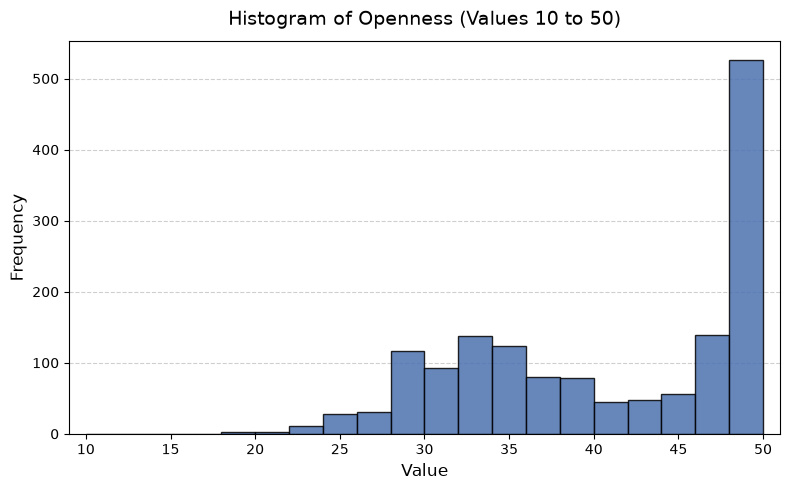

In [8]:
#!pip install matplotlib
%matplotlib inline
import io, os, json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Read Data
DATA_DIR = '../output/temp00/'
df_results = pd.read_csv('./scores_temp00_1529.csv')
print(df_results.shape)
print(df_results.head())

# 2. Define explicit bin edges to keep bins evenly spaced across [10, 50]
bin_edges = np.linspace(10, 50, 21)  # 20 bins of width 2

# 3. Create the histogram figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df_results['score_o'], bins=bin_edges, color="#4C72B0", edgecolor="black", alpha=0.85)

# 4. Configure labels, title, and limits
ax.set_title("Histogram of Openness (Values 10 to 50)", fontsize=14, pad=12)
ax.set_xlabel("Value", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_xlim(9, 51)

# 5. Add a light grid for scannability
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

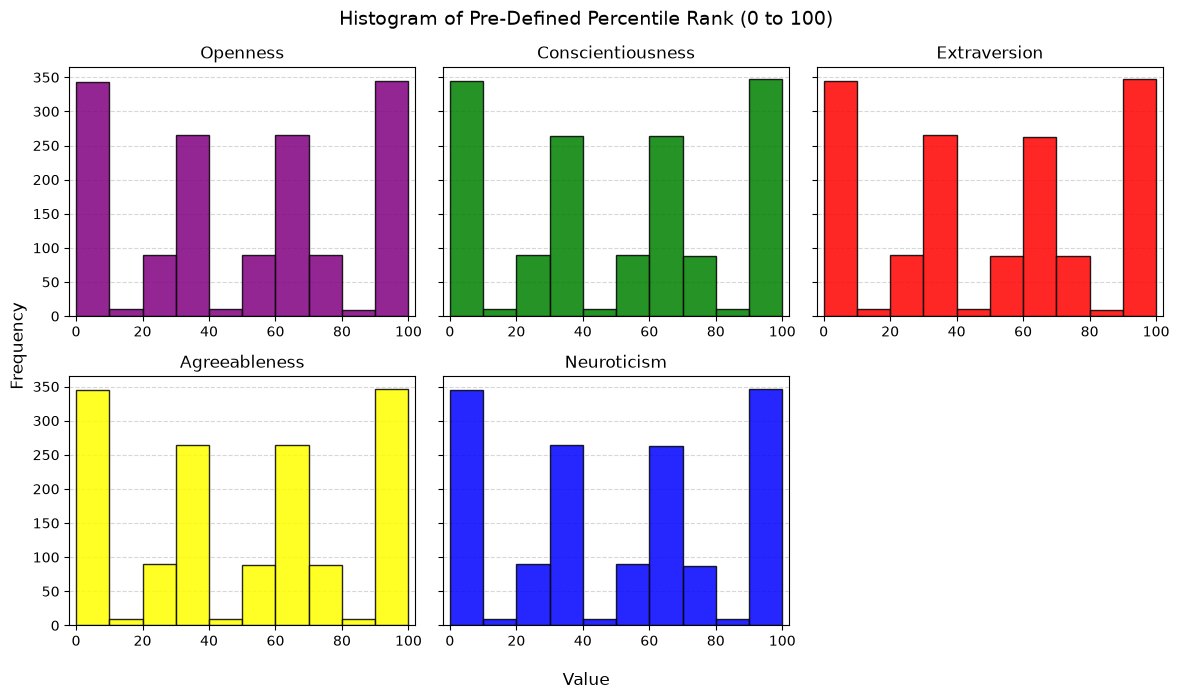

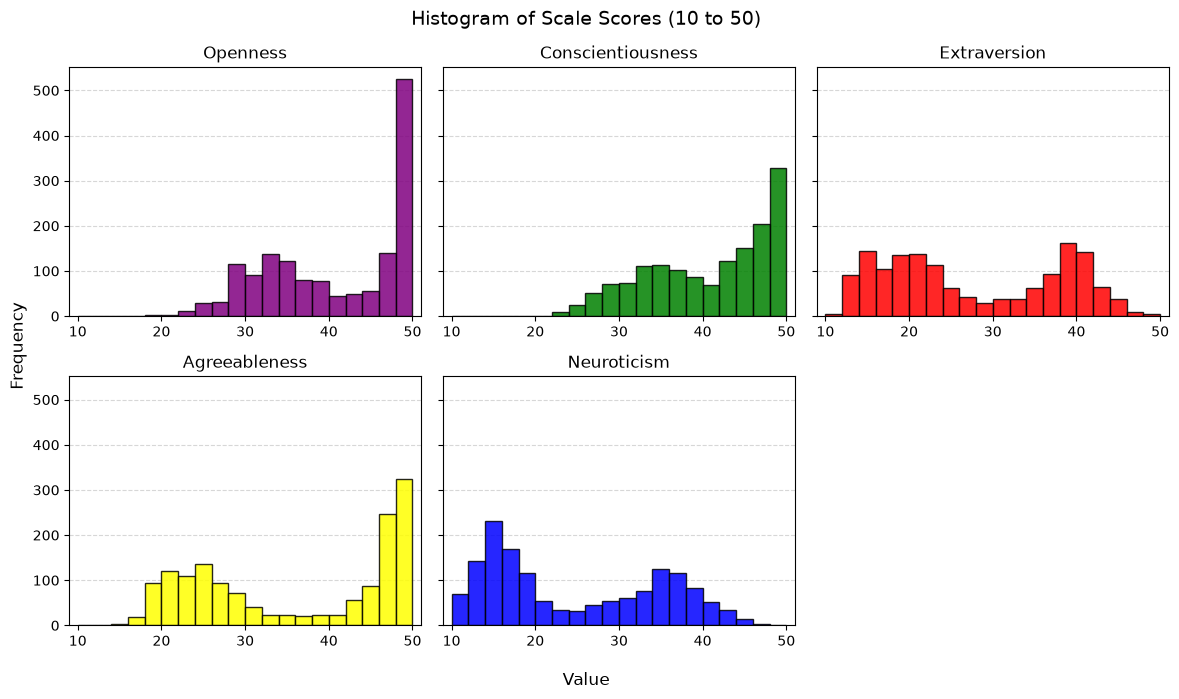

In [16]:
# Plot for OCEAN
presets = [df_results['pr_o_orig'],df_results['pr_c_orig'],df_results['pr_e_orig'],df_results['pr_a_orig'],df_results['pr_n_orig']]
datasets = [df_results['score_o'],df_results['score_c'],df_results['score_e'],df_results['score_a'],df_results['score_n']]
traits = ["Openness", "Conscientiousness", "Extraversion", "Agreeableness", "Neuroticism"]
colors = ["purple", "green", "red", "yellow", "blue"]

# For presets
bin_edges = np.linspace(0, 100, 11)  # 10 bins of width 5
# Set up a 2x3 figure layout
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12, 7), sharex=False, sharey=True)
flat_axes = axes.flatten()

# Plot each histogram using a consistent format
for i, (ax, data) in enumerate(zip(flat_axes, presets)):
    ax.hist(data, bins=bin_edges, color=colors[i], edgecolor="black", alpha=0.85)
    ax.set_title(traits[i], fontsize=12)
    ax.set_xlim(-2, 102)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

# Turn off the empty 6th subplot
flat_axes[5].axis("off")

# Global axis labels
fig.supxlabel("Value", fontsize=12)
fig.supylabel("Frequency", fontsize=12)
fig.suptitle("Histogram of Pre-Defined Percentile Rank (0 to 100)", fontsize=14, y=0.98)

plt.tight_layout()
plt.show()

# For Scale scores
bin_edges = np.linspace(10, 50, 21)  # 20 bins of width 2
# Set up a 2x3 figure layout
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12, 7), sharex=False, sharey=True)
flat_axes = axes.flatten()

# Plot each histogram using a consistent format
for i, (ax, data) in enumerate(zip(flat_axes, datasets)):
    ax.hist(data, bins=bin_edges, color=colors[i], edgecolor="black", alpha=0.85)
    ax.set_title(traits[i], fontsize=12)
    ax.set_xlim(9, 51)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

# Turn off the empty 6th subplot
flat_axes[5].axis("off")

# Global axis labels
fig.supxlabel("Value", fontsize=12)
fig.supylabel("Frequency", fontsize=12)
fig.suptitle("Histogram of Scale Scores (10 to 50)", fontsize=14, y=0.98)

plt.tight_layout()
plt.show()


From the figure above, we can see:

- The scores are not normally distributed. They are not similar to the predefined PR, either.
- For **Openness**, the distribution is extremely skewed to the right, which means the LLM used by default enforces a "high openness" personality.
- For **Conscientiousness**, the distribution is skewed to the right, but not as extreme as **Openness**. A minor Gaussian distribution is centered around 35.
- For **Extraversion**, the distribution shows one Gaussian at around 40 (agree) and a uniform distribution around 20.
- For **Agreeableness**, the distribution is similar to **Conscientiousness**, with a minor Gaussian distribution peak around 25.
- For **Neuroticism**, the distribution is skewed to the left (low) with a second Gaussian centered around 35.

Overall, the LLM shows certain default traits despite the personalities we assigned through pre-designed prompts. The default traits are: High openness, high conscientiousness, high agreeableness, and low neuroticism (i.e., high emotional stability). This is also the default setting in the RLHF process after pre-training LLMs to align their responses with "desirable behaviors."

These results may suggest that "attempts to control the LLM responses through personality" might not be able to override the LLM's default behaviors.

### Correlation Coefficient

Although the distributions of the scaled scores do not match the predefined percentile ranks, we can further check the correlation coefficients between the two sets.

In [13]:
df_results.corr()

,pr_o_orig,pr_c_orig,pr_e_orig,pr_a_orig,pr_n_orig,score_o,score_c,score_e,score_a,score_n
pr_o_orig,1.000000,0.209698,0.211841,0.208505,0.208392,0.840309,-0.247836,0.186710,0.176554,0.162584
pr_c_orig,0.209698,1.000000,0.210188,0.207377,0.205186,0.113151,0.652503,0.041657,0.114924,-0.006399
pr_e_orig,0.211841,0.210188,1.000000,0.211074,0.208885,0.166525,-0.025765,0.876817,0.221369,0.196003
pr_a_orig,0.208505,0.207377,0.211074,1.000000,0.206073,0.270792,0.142933,0.152544,0.890454,0.146741
pr_n_orig,0.208392,0.205186,0.208885,0.206073,1.000000,0.230352,-0.131172,0.179789,0.237041,0.855199
score_o,0.840309,0.113151,0.166525,0.270792,0.230352,1.000000,-0.269187,0.179015,0.290430,0.221688
score_c,-0.247836,0.652503,-0.025765,0.142933,-0.131172,-0.269187,1.000000,-0.202389,0.079186,-0.311207
score_e,0.186710,0.041657,0.876817,0.152544,0.179789,0.179015,-0.202389,1.000000,0.211286,0.241802
score_a,0.176554,0.114924,0.221369,0.890454,0.237041,0.290430,0.079186,0.211286,1.000000,0.233564
score_n,0.162584,-0.006399,0.196003,0.146741,0.855199,0.221688,-0.311207,0.241802,0.233564,1.000000


As shown in the table, the correlation coefficients between predefined percentile ranks and scaled scores are:

- "Openness": 0.84
- "Conscientiousness": 0.65
- "Extraversion": 0.88
- "Agreeableness": 0.89
- "Neuroticism": 0.86

The correlations are all very high except for "Conscientiousness". This may also be due to "alignment" during the RLHF procedure.

-----

### From Scale Scores to Percentile Rank

To calculate the percentile ranks of the scale scores, we need the norms (i.e., $\mu$ and $\sigma$) of the scores. Here we have two possible sources for the norms: the first is to derive them directly from the responses, and the second is to use the mean/std from other research.

#### 1. Public data

Because the International Personality Item Pool is an open-source framework, exact sample distributions shift slightly depending on the dataset. The values below represent the broadly accepted, benchmarked means ($\mu$) and standard deviations ($\sigma$) derived from massive public datasets (such as the Eugene-Springfield community sample data hosted by the Oregon Research Institute):

|Personality Trait (Scale Range: 10–50)|Population Mean ($\mu$)|Standard Deviation ($\sigma$)|
|--|--|--|
|Extraversion|30.5|7.5|
|Agreeableness|39.5|6.0|
|Conscientiousness|34.0|7.0|
|Emotional Stability (Neuroticism Inverse)|28.5|8.0|
|Intellect / Openness|35.5|6.0|

#### 2. Deriving from the synthesized responses

We can also derive the mean and standard deviation from the 1,516 responses.

### From Scale Score to Z-score

In [15]:
# Norms from the reference
mean_o_ref = 35.5
mean_c_ref = 34.0
mean_e_ref = 30.5
mean_a_ref = 39.5
mean_n_ref = 50 - 28.5
std_o_ref = 6.0
std_c_ref = 7.0
std_e_ref = 7.5
std_a_ref = 6.0
std_n_ref = 8.0

# Norms from the data
mean_o_obs = df_results['score_o'].mean()
mean_c_obs = df_results['score_c'].mean()
mean_e_obs = df_results['score_e'].mean()
mean_a_obs = df_results['score_a'].mean()
mean_n_obs = df_results['score_n'].mean()
std_o_obs = df_results['score_o'].std()
std_c_obs = df_results['score_c'].std()
std_e_obs = df_results['score_e'].std()
std_a_obs = df_results['score_a'].std()
std_n_obs = df_results['score_n'].std()

# Calculate Z scores
z_o_ref = (df_results['score_o'] - mean_o_ref)/std_o_ref
z_c_ref = (df_results['score_c'] - mean_c_ref)/std_c_ref
z_e_ref = (df_results['score_e'] - mean_e_ref)/std_e_ref
z_a_ref = (df_results['score_a'] - mean_a_ref)/std_a_ref
z_n_ref = (df_results['score_n'] - mean_n_ref)/std_n_ref
#
z_o_obs = (df_results['score_o'] - mean_o_obs)/std_o_obs
z_c_obs = (df_results['score_c'] - mean_c_obs)/std_c_obs
z_e_obs = (df_results['score_e'] - mean_e_obs)/std_e_obs
z_a_obs = (df_results['score_a'] - mean_a_obs)/std_a_obs
z_n_obs = (df_results['score_n'] - mean_n_obs)/std_n_obs


We illustrated the scale scores (green), z-score with reference norm (blue), and z-score with data-derived norm (orange). We can see:

1. The data doesn't seem normally distributed.
2. The z-scores derived from different norms seem different.

For now, we can be almost sure that LLM responses are biased. We will proceed to the percentile rank.


### From Z-score to Percentile

By assuming the scores are normally distributed, we can use the built-in [`statistics`](https://docs.python.org/3/library/statistics.html) module (Python 3.8+) to derive the percentile from the z-score. The [`NormalDist()`](https://docs.python.org/3/library/statistics.html#normaldist-objects) object is a tool for creating and manipulating normal distributions of a random variable. The function `statistics.NormalDist().cdf(x)` uses a cumulative distribution function (CDF), compute the probability that a random variable X will be less than or equal to x. Mathematically, it is written $P(X <= x)$.


In [ ]:
# Convert Z score to percentile
import statistics

def z_to_percentile(z):
    # statistics.NormalDist() defaults to mean=0 and std_dev=1
    cdf = statistics.NormalDist().cdf(z)
    return cdf * 100

